In [2]:
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from torchmetrics.classification import F1Score

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
# import seaborn as sns

from sklearn.metrics import ConfusionMatrixDisplay

from tqdm.notebook import trange, tqdm

import random
import time

random.seed(42)


# plt.style.use('seaborn-v0_8-darkgrid')
# sns.set_palette('husl')
torch.manual_seed(42)

In [19]:
# Hyperparamters
learning_rate = 1e-3
n_epochs = 20
# n_epochs = 10
batch_size = 32


In [4]:
label_mapping = {
    "LTR": 0,
    "Non-LTR/LINE": 1,
    "SINE": 2,
    "TIR": 3,
    "Helitron": 4,
    "Crypton": 5,
    "DIRS": 6,
    "Maverick": 7,
    "Penelope-like Element/PLE": 8
}

index_to_label = {number: name for name, number in label_mapping.items()}

sequence_encoding = {
    'A': [1, 0, 0, 0],
    'C': [0, 1, 0, 0],
    'G': [0, 0, 1, 0],
    'T': [0, 0, 0, 1]
}


In [5]:
""" Padding code from GLARE -> they used 4096 as their max_length """

# Random crop for training augmentation
# if self.augment and len(sequence) > self.max_length:
#     start = random.randint(0, len(sequence) - self.max_length)
#     sequence = sequence[start : start + self.max_length]

# # Reverse-complement augmentation (stochastic, training only).
# if self.rc_augment and random.random() < 0.5:
#     sequence = sequence.translate(RC_MAP)[::-1]

# encoding = self.tokenizer(
#     sequence,
#     return_tensors="pt",
#     padding="max_length",
#     truncation=True,
#     max_length=self.max_length,
#     pad_to_multiple_of=128,
# )

' Padding code from GLARE -> they used 4096 as their max_length '

In [6]:
# 4096 is what GLARE used.
# MAX_SEQ_LENGTH = 4096
# using 500 because it's soo slow
MAX_SEQ_LENGTH = 500

def custom_collate_fn(batch):
    """ Custom collate function for padding sequences up to the length of the longest sequence in the batch
    also returns the lengths of the sequences prior to padding """

    sequences, labels = zip(*batch)
    padded_sequences = pad_sequence(sequences, batch_first=True)
    lengths = torch.tensor([len(s) for s in sequences])
    
    return padded_sequences, lengths, torch.stack(labels)


def one_hot(sequence):
    encoded = []
    for nucleotide in sequence:
        encoded.append(sequence_encoding.get(nucleotide, [0,0,0,0]))
    return torch.tensor(encoded, dtype=torch.float32)


class CSVDataset(Dataset):
    
    def __init__(self, csv_file, max_length=MAX_SEQ_LENGTH, train=False):

        df = pd.read_csv(csv_file)
        
        self.sequences = [one_hot(s) for s in df["sequence_content"]]
        self.max_length = max_length
        self.train = train

        print(f"Longest sequence: {df["sequence_content"].str.len().max()}")
        print(f"Shortest sequence: {df["sequence_content"].str.len().min()}")
        print(f"Mean sequence length: {df["sequence_content"].str.len().mean()}")
        
        self.encoded_labels = df["TE_Order"].map(label_mapping)
        assert self.encoded_labels.notna().all(), df.loc[self.encoded_labels.isna(), "TE_Order"].unique()
        
        # self.X = torch.tensor(encoded_sequences, dtype=torch.float32)
        self.y = torch.tensor(self.encoded_labels, dtype=torch.long)
    
    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        sequence = self.sequences[idx]

        if len(sequence) > self.max_length:
            start = 0

            # using same train cropping technique as GLARE
            if self.train == True:
                start = random.randint(0, len(sequence) - self.max_length)
            # if there is time, replace this with GLARE's sliding window technique
            else:
                start = (len(sequence) - self.max_length) // 2
            
            sequence = sequence[start : start + self.max_length]
            

        return sequence, self.y[idx]

training_data = CSVDataset(
    csv_file="LSTMDataSets/PREPROCESSED_TE_feature_extraction_dataset_without_maverickpolinton.csv", 
    max_length=MAX_SEQ_LENGTH,
    train=True
)

testing_data = CSVDataset(
    csv_file="LSTMDataSets/FINAL_tester_with_targets.csv",
    max_length=MAX_SEQ_LENGTH,
)
# testing_data = CSVDataset(csv_file="Preprocessed/test.csv")

# for i in range(10):
     # print(training_data[i])



Longest sequence: 39893
Shortest sequence: 43
Mean sequence length: 2942.278810237491
Longest sequence: 24655
Shortest sequence: 130
Mean sequence length: 4647.4847972972975


In [7]:
data_loader_train = DataLoader(training_data, batch_size=batch_size, shuffle=True, collate_fn=custom_collate_fn)
data_loader_test = DataLoader(testing_data, batch_size=batch_size, shuffle=True, collate_fn=custom_collate_fn)

In [8]:
# contructor defines the layers
# forward describes how the data flows through the layers


class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()

        # LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True # needed to match order from collate function
        )

        # classification layer (fully connected)
        self.fc_out = nn.Linear(hidden_size, output_size)
    
    def forward(self, input_seqs, lengths):

        # output contains hidden state from each timestamp from final lstm layer
        # hidden_out is the final hidden state for each LSTM layer -> use -1 to get last layer
        packed_input_seqs = pack_padded_sequence(input_seqs, lengths.cpu(), batch_first=True, enforce_sorted=False)
        
        output, (hidden_out, mem_out) = self.lstm(packed_input_seqs)

        final_hidden = hidden_out[-1]

        return self.fc_out(final_hidden), hidden_out, mem_out
        
        


In [9]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(device)

mps


In [10]:
input_size = 4
hidden_size = 128
output_size = 9 # 9 TE output classes

num_layers = 1

# Create model
lstm_classifier = LSTM(input_size, hidden_size, output_size).to(device)

# Initialize the optimizer with the above parameters
optimizer = optim.Adam(lstm_classifier.parameters(), lr=learning_rate)

# since the training set is super inbalanced, make weights for loss function
counts = torch.bincount(training_data.y, minlength=output_size).float()
weights = counts.sum() / (counts.clamp(min=1) * output_size)
weights = weights.sqrt()
print(weights)
# Define the loss function
loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))


tensor([ 0.4888,  0.8139,  1.2162,  0.6947,  1.9464,  3.2437,  2.4729, 20.0393,
         5.5226])


In [11]:
num_model_params = 0

for param in lstm_classifier.parameters():
    num_model_params += param.flatten().shape[0]

print(f"The model has {num_model_params} parameters")

The model has 69769 parameters


In [12]:
training_loss_logger = []
test_loss_logger = []

training_acc_logger = []
testing_acc_logger = []

In [20]:
start = time.perf_counter()

for epoch in range(n_epochs):

    print (f"Epoch {epoch}")
    
    # set model to training mode
    lstm_classifier.train()
    steps = 0
    train_acc = 0

    # Go through training data
    for padded, lengths, labels in data_loader_train:

        padded = padded.to(device)
        labels = labels.to(device)
        
        # Initialize hidden and memory states
        hidden = torch.zeros(num_layers, batch_size, hidden_size, device = device)
        memory = torch.zeros(num_layers, batch_size, hidden_size, device = device)

        # forward pass
        pred, hidden, memory = lstm_classifier(padded, lengths)
    
        # loss calculation
        loss = loss_fn(pred, labels)
        
        # backpropagation and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # append training loss to logger
        training_loss_logger.append(loss.item())

        # calculate training accuracy
        train_acc += (pred.argmax(1) == labels).sum()
        steps += len(padded)

    train_acc = (train_acc/steps).item()
    print(train_acc)
    training_acc_logger.append(train_acc)
    end = time.perf_counter()

    print(f"Elapsed training time : {end - start:.6f} seconds")

    

Epoch 0
0.6216278672218323
Elapsed training time : 54.152488 seconds
Epoch 1
0.6280839443206787
Elapsed training time : 108.146893 seconds
Epoch 2
0.639843225479126
Elapsed training time : 161.778907 seconds
Epoch 3
0.6667742729187012
Elapsed training time : 215.245247 seconds
Epoch 4
0.6824533343315125
Elapsed training time : 270.431832 seconds
Epoch 5
0.6892783045768738
Elapsed training time : 325.521534 seconds
Epoch 6
0.6943048238754272
Elapsed training time : 380.587177 seconds
Epoch 7
0.7017754316329956
Elapsed training time : 435.988566 seconds
Epoch 8
0.699193000793457
Elapsed training time : 491.316517 seconds
Epoch 9
0.705971896648407
Elapsed training time : 546.579293 seconds
Epoch 10
0.7058796286582947
Elapsed training time : 602.452368 seconds
Epoch 11
0.705971896648407
Elapsed training time : 656.121263 seconds
Epoch 12
0.6803781390190125
Elapsed training time : 710.030465 seconds
Epoch 13
0.7134424448013306
Elapsed training time : 763.489550 seconds
Epoch 14
0.6593497991

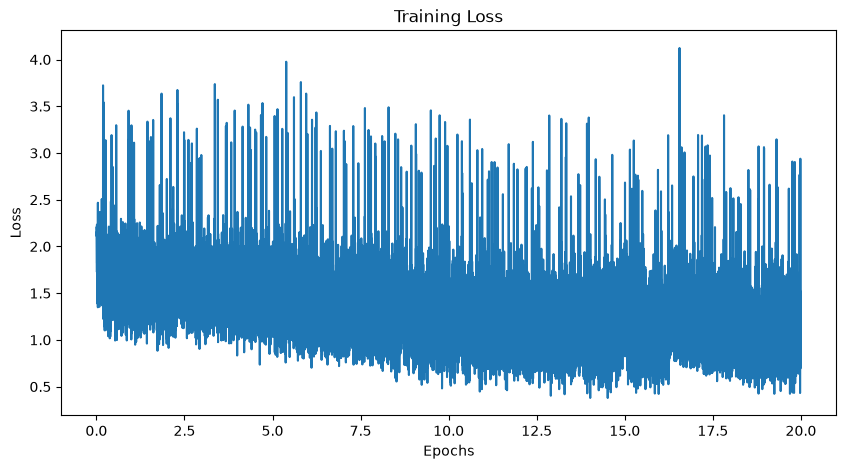

In [21]:
_ = plt.figure(figsize=(10, 5))
_ = plt.plot(np.linspace(0, n_epochs, len(training_loss_logger)), training_loss_logger)

_ = plt.title("Training Loss")
_ = plt.xlabel("Epochs")
_ = plt.ylabel("Loss")

In [23]:
print("Testing")

lstm_classifier.eval()
df_results = pd.DataFrame()

f1_metric = F1Score(task="multiclass", num_classes=output_size, average="macro")
f1_metric.to(device)

steps = 0
test_acc = 0

results_arr = np.array([], dtype=int)
labels_arr = np.array([], dtype=int)

with torch.no_grad():
    for padded, lengths, labels in data_loader_test:
    
        padded = padded.to(device)
        labels = labels.to(device)
    
        # Initialize hidden and memory states
        hidden = torch.zeros(num_layers, batch_size, hidden_size, device = device)
        memory = torch.zeros(num_layers, batch_size, hidden_size, device = device)
    
        # forward pass
        pred, hidden, memory = lstm_classifier(padded, lengths)


        
        # collect results
        results_array = pred.argmax(1).detach().cpu().numpy()
        results_arr = np.append(results_arr, results_array)

        labels_array = labels.detach().cpu().numpy()
        labels_arr = np.append(labels_arr, labels_array)
        
        f1_metric.update(pred, labels)
        
        test_acc += (pred.argmax(1) == labels).sum()
        steps += len(padded)

test_acc = (test_acc/steps).item()
test_f1 = f1_metric.compute()
print(f"Testing accuracy: {test_acc}")
print(f"Testing F1 score: {test_f1}")

df = pd.DataFrame({
    "Predicted_Label": results_arr,
    "Actual_Label": labels_arr
})

df["Predicted_Label"] = df["Predicted_Label"].map(index_to_label)
df["Actual_Label"] = df["Actual_Label"].map(index_to_label)

# print(df["Actual_Label"].value_counts())

# print(df)

Testing
Testing accuracy: 0.3057432472705841
Testing F1 score: 0.1148795634508133


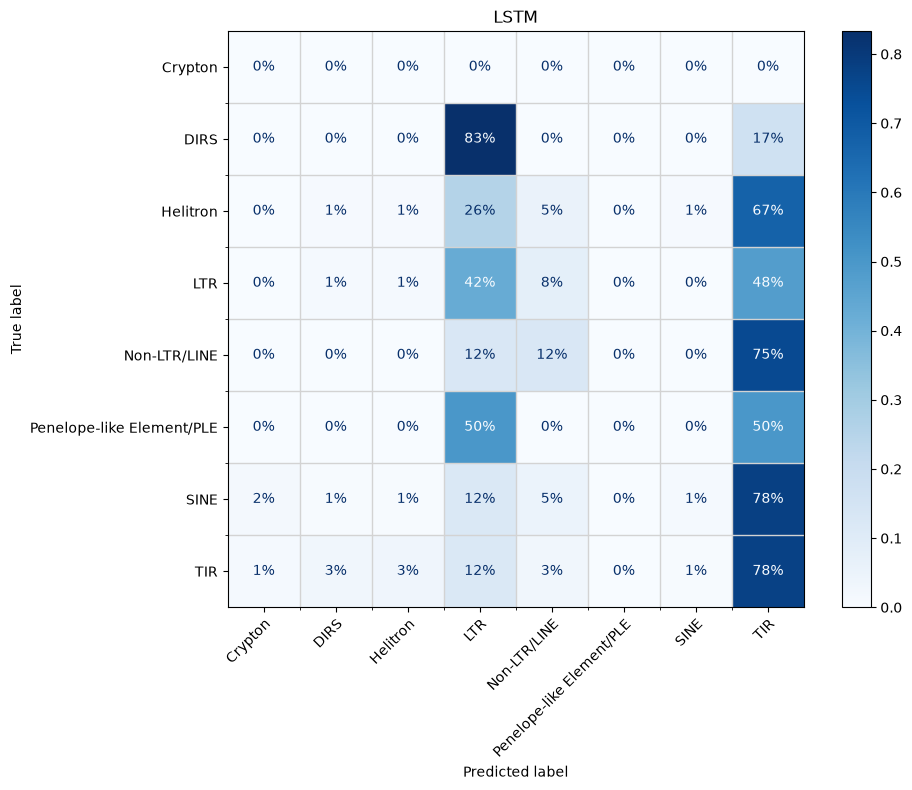

In [24]:
y_true = df["Actual_Label"]
y_pred = df["Predicted_Label"].fillna("UNKNOWN")
labels = sorted(set(y_true) | set(y_pred))

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=labels, normalize="true",
    cmap="Blues", values_format=".0%", xticks_rotation=45, ax=ax,
)
# disp.ax_.set_title(f" {accuracy:.1%} F1: {f1:.1%}")
disp.ax_.set_title(f"LSTM")

# anchor the end of each rotated label to its tick so long labels don't spill under the next column
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")

# gridlines between cells
ax.set_xticks([x + 0.5 for x in range(len(labels) - 1)], minor=True)
ax.set_yticks([y + 0.5 for y in range(len(labels) - 1)], minor=True)
ax.grid(which="minor", color="lightgray", linewidth=1)
plt.tight_layout()
# plt.savefig(plot_png, dpi=200)